# Practice 09 — CNN Pipeline

**Goal:** run one image pipeline with two models, so the scores differ by the model, not the data.

| Model | Weights |
|:---|:---|
| VGG-11 | trained from scratch |
| ResNet18 | pretrained on ImageNet, last block and classifier fine-tuned |

| Step | What it produces |
|:---|:---|
| Data | train / validation / test split, augmented, wrapped in `DataLoader` |
| `train` / `evaluate` | the epoch loop and the no-grad evaluation, written once |
| Models | two `nn.Module`s returning logits |
| Diagnostics | learning curves, final test score, confusion matrix |

- Data → CIFAR-10: 32×32 colour photographs, 10 classes, resized to 96×96

---
## Step 0. Imports and Setup

In [1]:
import time

import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

np.random.seed(42)
torch.manual_seed(42)

plt.rcParams['axes.unicode_minus'] = False

# a GPU is worth having here; on a CPU-only machine .to(device) is a no-op and the run takes minutes
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cuda


---
## Step 1. Data

| Set | Size | Source | Transform |
|:---|:---|:---|:---|
| Train | 10000 | training split | resize, crop, flip, normalize |
| Validation | 2000 | training split | resize, normalize |
| Test | 2000 | test split | resize, normalize |

- Random crop and flip → training only; evaluation has to be deterministic
- ImageNet normalization for both models → the statistics ResNet18 was pretrained with

In [2]:
# published ImageNet statistics, the ones the pretrained weights were fitted under
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

transform_train = transforms.Compose([
    transforms.Resize(96),
    transforms.RandomCrop(96, padding=8),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

transform_eval = transforms.Compose([
    transforms.Resize(96),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

cifar_train_augmented = torchvision.datasets.CIFAR10(
    root='./data', train=True,  download=True, transform=transform_train)
cifar_train_plain = torchvision.datasets.CIFAR10(
    root='./data', train=True,  download=True, transform=transform_eval)
cifar_test = torchvision.datasets.CIFAR10(
    root='./data', train=False, download=True, transform=transform_eval)

# the validation images come out of the training split, so the test split stays untouched until the end
train_set = Subset(cifar_train_augmented, range(10000))
val_set   = Subset(cifar_train_plain, range(10000, 12000))
test_set  = Subset(cifar_test, range(2000))

train_loader = DataLoader(train_set, batch_size=64,  shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=128, shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=128, shuffle=False)

class_names = cifar_test.classes
y_test = np.array(cifar_test.targets[:2000])

print(f'train: {len(train_set)}, val: {len(val_set)}, test: {len(test_set)}')
print(f'batches per epoch - train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}')

X_batch, Y_batch = next(iter(train_loader))
print(f'one batch - X {tuple(X_batch.shape)} {X_batch.dtype}, Y {tuple(Y_batch.shape)} {Y_batch.dtype}')

train: 10000, val: 2000, test: 2000
batches per epoch - train: 157, val: 16, test: 16
one batch - X (64, 3, 96, 96) torch.float32, Y (64,) torch.int64


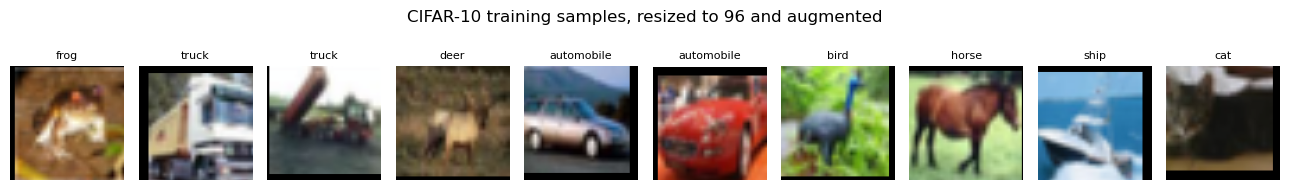

In [3]:
# turns a normalized (C, H, W) tensor back into an (H, W, C) array that imshow can display
def unnormalize(image_tensor):
    image = image_tensor.permute(1, 2, 0).numpy()
    image = image * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    return np.clip(image, 0, 1)


fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
for i in range(10):
    image, label = train_set[i]
    axes[i].imshow(unnormalize(image))
    axes[i].set_title(class_names[label], fontsize=8)
    axes[i].axis('off')
plt.suptitle('CIFAR-10 training samples, resized to 96 and augmented', y=1.05)
plt.tight_layout(); plt.show()

---
## Step 2. `train` and `evaluate`

| Function | Does | Returns |
|:---|:---|:---|
| `evaluate(model, loader, device)` | one pass, gradients off | `(loss, accuracy, y_pred)` |
| `train(model, train_loader, val_loader, optimizer, epochs, device)` | epoch loop, `evaluate` on `val_loader` each epoch | `(train_losses, train_accs, val_losses, val_accs)` |

- Neither names a model or dataset → the second model reuses both unchanged
- Only `val_loader` inside `train` → the test set must not steer the choice of model

In [4]:
def evaluate(model, loader, device):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    loss_sum, correct, count = 0.0, 0, 0
    preds = []
    with torch.no_grad():
        for X_batch, Y_batch in loader:
            X_batch = X_batch.to(device)
            Y_batch = Y_batch.to(device)

            output = model(X_batch)
            loss_sum += criterion(output, Y_batch).item()
            correct += (output.argmax(1) == Y_batch).sum().item()
            count += len(Y_batch)
            preds.append(output.argmax(1).cpu())

    y_pred = torch.cat(preds).numpy()
    return loss_sum / len(loader), correct / count, y_pred

In [5]:
def train(model, train_loader, val_loader, optimizer, epochs, device):
    criterion = nn.CrossEntropyLoss()
    train_losses, train_accs, val_losses, val_accs = [], [], [], []
    for epoch in range(epochs):
        model.train()
        loss_sum, correct, count = 0.0, 0, 0
        for X_batch, Y_batch in train_loader:
            X_batch = X_batch.to(device)
            Y_batch = Y_batch.to(device)

            output = model(X_batch)               # logits, (batch, 10)
            loss = criterion(output, Y_batch)

            optimizer.zero_grad()                 # clear the accumulated gradients
            loss.backward()                       # autograd computes the gradients
            optimizer.step()                      # the optimizer updates the parameters

            loss_sum += loss.item()
            correct += (output.argmax(1) == Y_batch).sum().item()
            count += len(Y_batch)

        train_loss = loss_sum / len(train_loader)
        train_acc = correct / count
        val_loss, val_acc, _ = evaluate(model, val_loader, device)

        train_losses.append(train_loss)
        train_accs.append(train_acc)
        val_losses.append(val_loss)
        val_accs.append(val_acc)

        print(f'  Epoch {epoch+1:2d}/{epochs}  '
              f'train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  '
              f'train_acc={train_acc:.4f}  val_acc={val_acc:.4f}')
    return train_losses, train_accs, val_losses, val_accs

In [6]:
epochs = 15

print(f'Loss      : {nn.CrossEntropyLoss()}')
print(f'Optimizer : SGD with momentum 0.9')
print(f'Epochs    : {epochs}')

Loss      : CrossEntropyLoss()
Optimizer : SGD with momentum 0.9
Epochs    : 15


---
## Step 3. VGGNet from Scratch

- Only 3×3 convolutions, stride 1 → depth is the only design variable
- Two stacked 3×3 layers see the 5×5 window of one 5×5 layer → fewer weights, one more non-linearity
- VGG-11 = 8 convolutions in 5 blocks + 3 linear layers; each block ends in a pool that halves the resolution

- Two departures from the 2014 paper → the deep stack trains in one run on this data; the convolutional stack is unchanged

| Here | In the paper |
|:---|:---|
| `BatchNorm2d` after every convolution | no normalization; deeper configurations were started from a shallower trained one |
| Classifier 512-512-10 | 4096-4096-1000, which on ten classes at 96×96 would hold most of the parameters |

In [7]:
class VGG11(nn.Module):
    def __init__(self):
        super().__init__()
        # block 1 - one convolution, 96 -> 48
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2))

        # block 2 - one convolution, 48 -> 24
        self.block2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2))

        # block 3 - two convolutions, 24 -> 12
        self.block3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256), nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256), nn.ReLU(),
            nn.MaxPool2d(2))

        # block 4 - two convolutions, 12 -> 6
        self.block4 = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512), nn.ReLU(),
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512), nn.ReLU(),
            nn.MaxPool2d(2))

        # block 5 - two convolutions, 6 -> 3
        self.block5 = nn.Sequential(
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512), nn.ReLU(),
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512), nn.ReLU(),
            nn.MaxPool2d(2))

        self.classifier = nn.Sequential(
            nn.Linear(512 * 3 * 3, 512), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(512, 512), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(512, 10))

        # He initialization, matched to the ReLU that follows each convolution
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode='fan_out', nonlinearity='relu')

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.block5(x)
        x = x.flatten(1)          # keep the batch axis, flatten the rest
        z = self.classifier(x)    # logits; the softmax is applied inside the loss
        return z


torch.manual_seed(42)
model_vgg = VGG11().to(device)
print(f'VGG-11 parameters: {sum(p.numel() for p in model_vgg.parameters()):,}')

VGG-11 parameters: 11,853,578


In [8]:
# the shape after each block, which is where 512 * 3 * 3 in the first linear layer comes from
x = torch.randn(1, 3, 96, 96).to(device)
print(f'input          : {tuple(x.shape)}')

x = model_vgg.block1(x)
print(f'after block1   : {tuple(x.shape)}')

x = model_vgg.block2(x)
print(f'after block2   : {tuple(x.shape)}')

x = model_vgg.block3(x)
print(f'after block3   : {tuple(x.shape)}')

x = model_vgg.block4(x)
print(f'after block4   : {tuple(x.shape)}')

x = model_vgg.block5(x)
print(f'after block5   : {tuple(x.shape)}')

print(f'after flatten  : {tuple(x.flatten(1).shape)}')

input          : (1, 3, 96, 96)


after block1   : (1, 64, 48, 48)
after block2   : (1, 128, 24, 24)
after block3   : (1, 256, 12, 12)
after block4   : (1, 512, 6, 6)
after block5   : (1, 512, 3, 3)
after flatten  : (1, 4608)


In [9]:
optimizer_vgg = torch.optim.SGD(model_vgg.parameters(), lr=0.01, momentum=0.9)

torch.manual_seed(42)   # train_loader shuffles and augments from the same state for both models
print(f'Training VGG-11 from scratch on {device} ...')
start = time.time()
train_losses_vgg, train_accs_vgg, val_losses_vgg, val_accs_vgg = train(
    model_vgg, train_loader, val_loader, optimizer_vgg, epochs=epochs, device=device)
print()
print(f'elapsed: {time.time() - start:.1f}s')
print(f'final val_acc={val_accs_vgg[-1]:.4f}  (best {max(val_accs_vgg):.4f})')

Training VGG-11 from scratch on cuda ...


  Epoch  1/15  train_loss=1.9831  val_loss=1.8246  train_acc=0.2451  val_acc=0.3165


  Epoch  2/15  train_loss=1.7527  val_loss=1.6052  train_acc=0.3335  val_acc=0.3765


  Epoch  3/15  train_loss=1.6547  val_loss=1.6018  train_acc=0.3740  val_acc=0.3965


  Epoch  4/15  train_loss=1.5417  val_loss=1.4688  train_acc=0.4270  val_acc=0.4555


...

  Epoch 11/15  train_loss=1.0892  val_loss=1.0928  train_acc=0.6221  val_acc=0.6240


  Epoch 12/15  train_loss=1.0273  val_loss=1.0389  train_acc=0.6393  val_acc=0.6395


  Epoch 13/15  train_loss=0.9884  val_loss=1.0145  train_acc=0.6531  val_acc=0.6625


  Epoch 14/15  train_loss=0.9537  val_loss=1.0882  train_acc=0.6654  val_acc=0.6360


  Epoch 15/15  train_loss=0.9150  val_loss=1.0336  train_acc=0.6824  val_acc=0.6625

elapsed: 130.7s
final val_acc=0.6625  (best 0.6625)


---
## Step 4. Pretrained ResNet18

| Part | `requires_grad` | Why |
|:---|:---|:---|
| `conv1` … `layer3` | `False` | general visual features, kept |
| `layer4` | `True` | specific to the original task |
| `fc` → a new `Linear(512, 10)` | `True`, by construction | 1000 ImageNet classes → 10 |

- The optimizer gets only the trainable parameters → frozen weights are never updated
- `model.train()` still updates BatchNorm running statistics in the frozen blocks

In [10]:
torch.manual_seed(42)
model_resnet = resnet18(weights=ResNet18_Weights.DEFAULT)

for parameter in model_resnet.parameters():
    parameter.requires_grad = False
for parameter in model_resnet.layer4.parameters():
    parameter.requires_grad = True

model_resnet.fc = nn.Linear(model_resnet.fc.in_features, 10)   # 1000 ImageNet classes -> 10
model_resnet = model_resnet.to(device)

total_parameters = sum(p.numel() for p in model_resnet.parameters())
trainable_parameters = sum(p.numel() for p in model_resnet.parameters() if p.requires_grad)
print(f'total     parameters: {total_parameters:,}')
print(f'trainable parameters: {trainable_parameters:,}  ({trainable_parameters / total_parameters:.1%})')

# the classifier is random at this point, so the accuracy should sit near chance level, 10%
_, accuracy_before, _ = evaluate(model_resnet, val_loader, device)
print(f'val_acc before fine-tuning: {accuracy_before:.4f}')

total     parameters: 11,181,642
trainable parameters: 8,398,858  (75.1%)


val_acc before fine-tuning: 0.0795


- `layer4` + `fc` = 75.1% of the parameters → the last block is most of the network
- 0.08 before fine-tuning → chance level (0.10)

In [11]:
trainable = [p for p in model_resnet.parameters() if p.requires_grad]
optimizer_resnet = torch.optim.SGD(trainable, lr=0.001, momentum=0.9)

torch.manual_seed(42)   # train_loader shuffles and augments from the same state for both models
print(f'Fine-tuning ResNet18 on {device} ...')
start = time.time()
train_losses_resnet, train_accs_resnet, val_losses_resnet, val_accs_resnet = train(
    model_resnet, train_loader, val_loader, optimizer_resnet, epochs=epochs, device=device)
print()
print(f'elapsed: {time.time() - start:.1f}s')
print(f'final val_acc={val_accs_resnet[-1]:.4f}  (best {max(val_accs_resnet):.4f})')

Fine-tuning ResNet18 on cuda ...


  Epoch  1/15  train_loss=1.3505  val_loss=0.8596  train_acc=0.5410  val_acc=0.7070


  Epoch  2/15  train_loss=0.7626  val_loss=0.6879  train_acc=0.7377  val_acc=0.7615


  Epoch  3/15  train_loss=0.6326  val_loss=0.6043  train_acc=0.7797  val_acc=0.7950


  Epoch  4/15  train_loss=0.5487  val_loss=0.5681  train_acc=0.8119  val_acc=0.8060


...

  Epoch 11/15  train_loss=0.3113  val_loss=0.4803  train_acc=0.8937  val_acc=0.8390


  Epoch 12/15  train_loss=0.2896  val_loss=0.4597  train_acc=0.9012  val_acc=0.8420


  Epoch 13/15  train_loss=0.2650  val_loss=0.4678  train_acc=0.9088  val_acc=0.8380


  Epoch 14/15  train_loss=0.2523  val_loss=0.4603  train_acc=0.9134  val_acc=0.8430


  Epoch 15/15  train_loss=0.2300  val_loss=0.4783  train_acc=0.9219  val_acc=0.8445

elapsed: 85.4s
final val_acc=0.8445  (best 0.8445)


---
## Step 5. Comparison

| | VGG-11 | ResNet18 |
|:---|:---|:---|
| Model | 11 weight layers, from scratch | pretrained, `layer4` and `fc` trained |
| Learning rate | 0.01 | 0.001 |

- **Fixed** → loaders, input size, augmentation, batch size, epochs, SGD with momentum 0.9, seed before construction and before training
- The learning rate differs too → it belongs to the pretraining: at 0.01 the pretrained weights would move too far from where they started

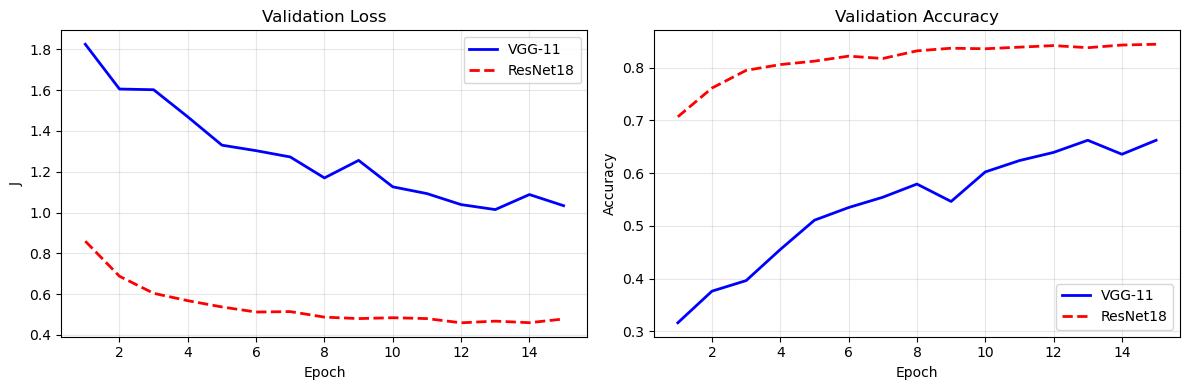

best val_acc - vgg: 0.6625, resnet: 0.8445


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs_range = range(1, epochs + 1)

axes[0].plot(epochs_range, val_losses_vgg, 'b-',  linewidth=2, label='VGG-11')
axes[0].plot(epochs_range, val_losses_resnet, 'r--', linewidth=2, label='ResNet18')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('J')
axes[0].set_title('Validation Loss'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, val_accs_vgg, 'b-',  linewidth=2, label='VGG-11')
axes[1].plot(epochs_range, val_accs_resnet, 'r--', linewidth=2, label='ResNet18')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Validation Accuracy'); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

print(f'best val_acc - vgg: {max(val_accs_vgg):.4f}, resnet: {max(val_accs_resnet):.4f}')

- VGG-11 → 0.32 to 0.66, flat over the last three epochs; train accuracy 0.68 ≈ validation and still rising: undertrained, not overfitted
- ResNet18 → 0.71 after one epoch, flat near 0.84 from epoch 9
- Eleven weight layers on 10000 images → need more epochs or more data

---
## Step 6. Final Test Evaluation

- The choice between the models was made on validation → read the test split now, once per model

In [13]:
test_loss_vgg, test_acc_vgg, y_pred_vgg = evaluate(model_vgg, test_loader, device)
test_loss_resnet, test_acc_resnet, y_pred_resnet = evaluate(model_resnet, test_loader, device)

print(f'VGG-11    test_loss={test_loss_vgg:.4f}  test_acc={test_acc_vgg:.4f}')
print(f'ResNet18  test_loss={test_loss_resnet:.4f}  test_acc={test_acc_resnet:.4f}')

VGG-11    test_loss=1.0083  test_acc=0.6675
ResNet18  test_loss=0.4763  test_acc=0.8370


- Test 0.67 vs. 0.84, validation 0.66 vs. 0.84 → the validation split was a fair guide

---
## Step 7. Where the Errors Are

- Accuracy counts the errors, it does not locate them
- `shuffle=False` → `y_pred_resnet` is aligned with `test_set`, so each index points back at its image
- Confusion matrix → off-diagonal entries name the class pairs being confused

misclassified: 326 of 2000 test images


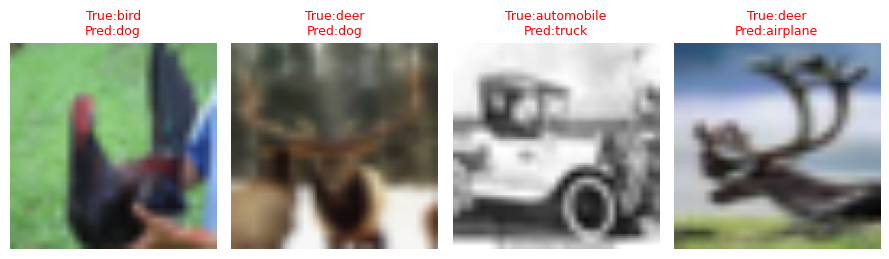

In [14]:
wrong_index = np.where(y_pred_resnet != y_test)[0]
print(f'misclassified: {len(wrong_index)} of {len(y_test)} test images')

fig, axes = plt.subplots(1, 4, figsize=(9, 2.8))
for i in range(4):
    index = wrong_index[i]
    image, _ = test_set[index]
    axes[i].imshow(unnormalize(image))
    axes[i].set_title(f'True:{class_names[y_test[index]]}\nPred:{class_names[y_pred_resnet[index]]}',
                      color='red', fontsize=9)
    axes[i].axis('off')
plt.tight_layout(); plt.show()

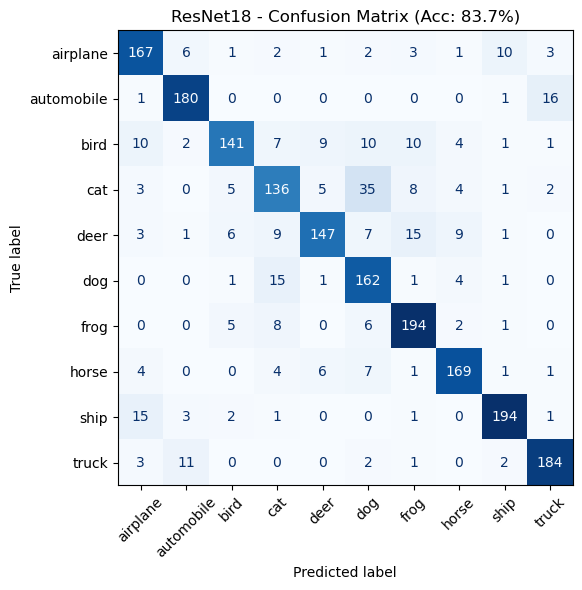

In [15]:
fig, ax = plt.subplots(figsize=(7, 6))
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, y_pred_resnet), display_labels=class_names)
display_matrix.plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45)
ax.set_title(f'ResNet18 - Confusion Matrix (Acc: {test_acc_resnet:.1%})')
plt.tight_layout(); plt.show()

- 326 errors in 2000 → the largest off-diagonal entry: 35 cats read as dogs

---
## Summary

- Pipeline = loaders, `train` / `evaluate`, a model, diagnostics → swapping the model left the other three untouched
- Same 15 epochs → test accuracy 0.67 for VGG-11 from scratch, 0.84 for ResNet18 starting from ImageNet features
- Models compared on validation → test split read once, afterwards

---
## Exercises

1. Unfreeze `layer3` as well — what does the trainable fraction become, and does accuracy follow?
2. Drop the augmentation from `transform_train`, retrain VGG-11 — which curve moves, train or validation?
3. Swap `resnet18` for `resnet34` or `mobilenet_v2` (head: `classifier[1]`) — compare accuracy against run time.
4. Load your own photographs (`data/my_photos/<class>/<file>.jpg`) with `torchvision.datasets.ImageFolder` — fine-tune the same ResNet18.

In [16]:
# Write your code here